# Logística en Baja California
## Fase 1: Exploración Inicial

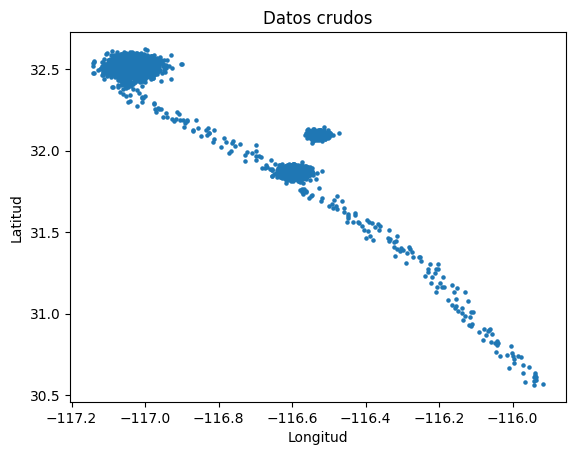

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler

df_raw = pd.read_csv('dataassets/logistica_baja_california.csv')

latitud = np.array(df_raw['Latitud'])
longitud = np.array(df_raw['Longitud'])
df = df_raw[['Latitud','Longitud']].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)


plt.scatter(longitud, latitud, s=5)
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.title('Datos crudos')
plt.show()

## Fase 2: Misión Estratégica
Usamos KMeans porque busca 3 centros y minimiza la distancia de cada punto a su centro.

[[  32.50631573 -117.03496385]
 [  31.04053982 -116.13802721]
 [  31.91234754 -116.58072818]]


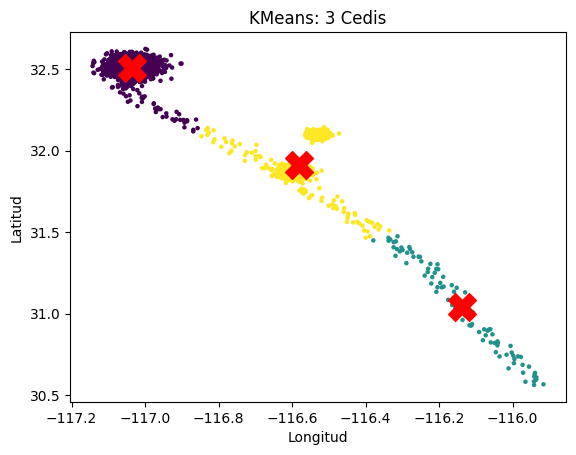

In [2]:
model = KMeans(n_clusters=3, random_state=42)
labels_kmeans = model.fit_predict(X_scaled)
df['cluster_kmeans'] = labels_kmeans

# Los centros salen escalados, los regresamos a grados reales
cluster_centers = scaler.inverse_transform(model.cluster_centers_)
print(cluster_centers)  # columnas: [Latitud, Longitud]


plt.scatter(df['Longitud'], df['Latitud'], c=df['cluster_kmeans'], s=5)
plt.scatter(cluster_centers[:,1], cluster_centers[:,0], marker='X', c='red', s=400)
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.title('KMeans: 3 Cedis')
plt.show()

### Análisis
¿Dónde colocó el algoritmo las Cedis? ¿Hacen sentido?

Una Cedis quedó en Tijuana, esa sí tiene sentido. Otra quedó entre Ensenada y el Valle de Guadalupe, porque juntó las dos zonas en un solo grupo y el centro quedó en medio. La tercera quedó en la carretera al sur, donde casi no hay solicitudes, entonces no tiene mucho sentido poner una Cedis ahí.

¿Por qué la matemática del algoritmo provocó esto?

KMeans mete todos los puntos en algún cluster, incluso los ranchos aislados, y el centro es el promedio de los puntos del cluster. Como los puntos del sur están muy lejos de todo, el algoritmo usa un centro solo para ellos aunque sean pocos.

## Fase 3: Misión Operativa
Usamos DBSCAN porque agrupa por densidad y los puntos aislados los marca como ruido (-1).

Clusters encontrados: 3
cluster_dbscan
 0    1569
 1    1019
 2     300
-1     212
Name: count, dtype: int64


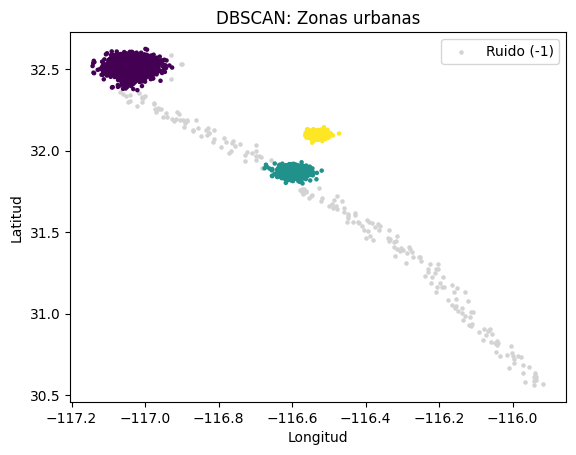

In [3]:
dbscan_model = DBSCAN(eps=0.1, min_samples=20)
labels_dbscan = dbscan_model.fit_predict(X_scaled)
df['cluster_dbscan'] = labels_dbscan

print('Clusters encontrados:', len(set(labels_dbscan)) - 1)
print(df['cluster_dbscan'].value_counts())

ruido = df[df['cluster_dbscan'] == -1]
urbano = df[df['cluster_dbscan'] != -1]


plt.scatter(ruido['Longitud'], ruido['Latitud'], c='lightgray', s=5, label='Ruido (-1)')
plt.scatter(urbano['Longitud'], urbano['Latitud'], c=urbano['cluster_dbscan'], s=5)
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.title('DBSCAN: Zonas urbanas')
plt.legend()
plt.show()

In [4]:
# Centro aproximado de cada mancha urbana
print(urbano.groupby('cluster_dbscan')[['Latitud','Longitud']].mean())

                  Latitud    Longitud
cluster_dbscan                       
0               32.512586 -117.037141
1               31.867229 -116.595587
2               32.096538 -116.530044


### Análisis
¿Usaron el mismo algoritmo que en la misión anterior?

No, en la fase 2 usamos KMeans y en esta usamos DBSCAN.

¿De no ser así, por qué se comportaron diferentes?

KMeans usa distancias y promedios y obliga a que todos los puntos estén en un grupo, por eso el ruido mueve los centros. DBSCAN solo forma grupos donde hay muchos puntos juntos y los que están dispersos los deja como ruido, entonces los ranchos no afectan a las ciudades.

¿A qué ciudades reales corresponden las 3 manchas urbanas?

- Cluster 0: Tijuana
- Cluster 1: Ensenada
- Cluster 2: Valle de Guadalupe